# Exercise II: Classification of Iris Flowers
Think about which libraries and frameworks could be used for this exercise.

In [ ]:
# pro tip: use ruff to format code
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42

# Loading the Data
Please use the Dataset Iris_Data.csv you will find in StudOn.
Get an overview of the data structure.
Comment your code briefly.
To use data you can:

*   You can upload the data right here in the notebook on the left-hand side
*   You can upload the data to Google Drive and then connect it to Colab


Which columns or values represent the features, and which represent the target variable?

In [7]:
# load the dataset
df = pd.read_csv("Iris_Data.csv")

print("Shape:", df.shape)
display(df.head())
df.info()
display(df.describe())

# features = the four measurements, target = the species label
feature_cols = ["sepal_length_cm", "sepal_width_cm", "petal_length_cm", "petal_width_cm"]
target_col = "species"
X = df[feature_cols]
y = df[target_col]
print("Features:", feature_cols)
print("Target:  ", target_col, "->", sorted(y.unique()))

Shape: (150, 5)


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   sepal_length_cm  150 non-null    float64
 1   sepal_width_cm   150 non-null    float64
 2   petal_length_cm  150 non-null    float64
 3   petal_width_cm   150 non-null    float64
 4   species          150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


Features: ['sepal_length_cm', 'sepal_width_cm', 'petal_length_cm', 'petal_width_cm']
Target:   species -> ['setosa', 'versicolor', 'virginica']


The dataset has 150 rows and 5 columns with no missing values.

* **Features (X)**: sepal_length_cm, sepal_width_cm, petal_length_cm, petal_width_cm
* **Target (y)**: species (setosa, versicolor, virginica)

Since $y$ is categorical, this is a classification problem.

---

# Understanding the Data
How many flowers are there per species? Are there missing values?
Compare the mean values of the features for each species.
Which features differ most between the species, and is this plausible?

In [15]:
# Number of flowers per species
print("Flowers per species:")
print(y.value_counts(), "\n")

# Missing values per column
print("Missing values per column:")
print(df.isnull().sum(), "\n")

# Mean of each feature per species
means = df.groupby(target_col)[feature_cols].mean()
display(means.round(2))

Flowers per species:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64 

Missing values per column:
sepal_length_cm    0
sepal_width_cm     0
petal_length_cm    0
petal_width_cm     0
species            0
dtype: int64 



,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


- There are 50 flowers per species.
- Again: No missing values.
- The petal length and petal width differ the most between species. Seems reasonable (I mean they are different flowers)...

---

# Visualize the Data
Visualize the distribution of each feature per species (e.g. histograms) and the relationships between features (e.g. scatter plots, coloured by species).
Which feature pairs separate the species best? Which species are hard to distinguish?

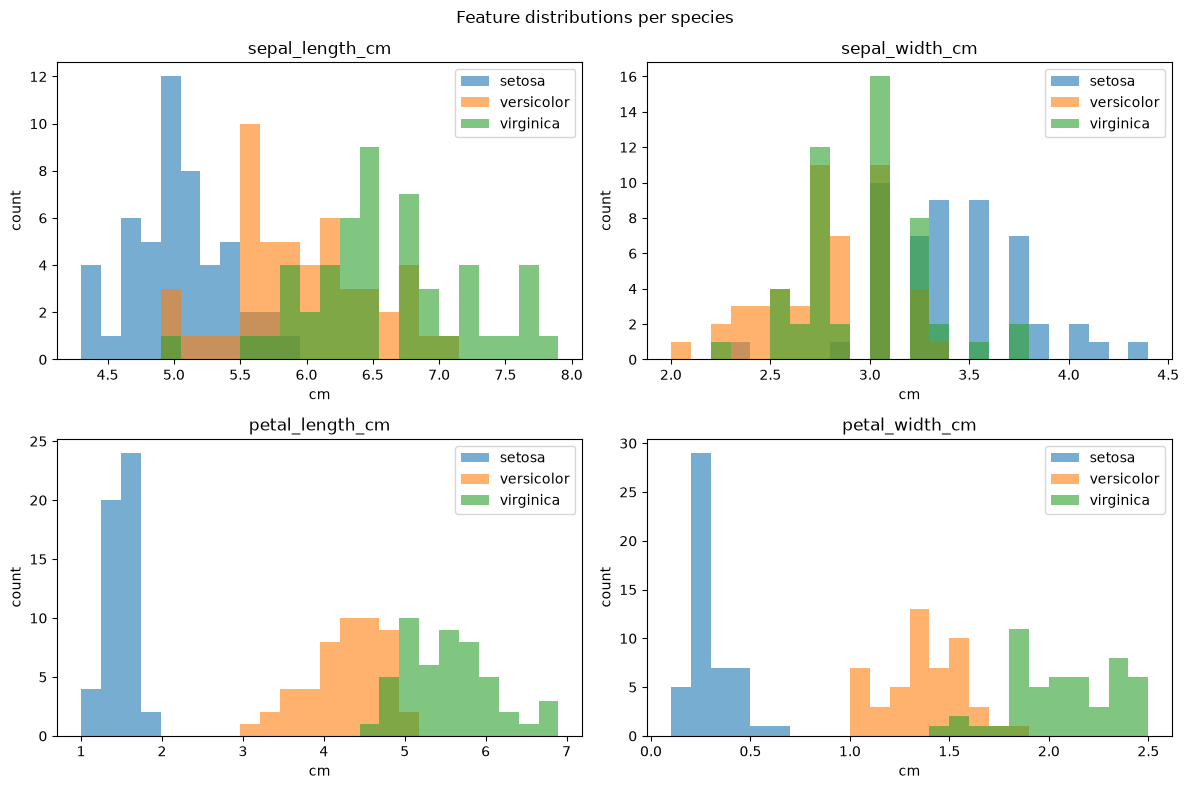

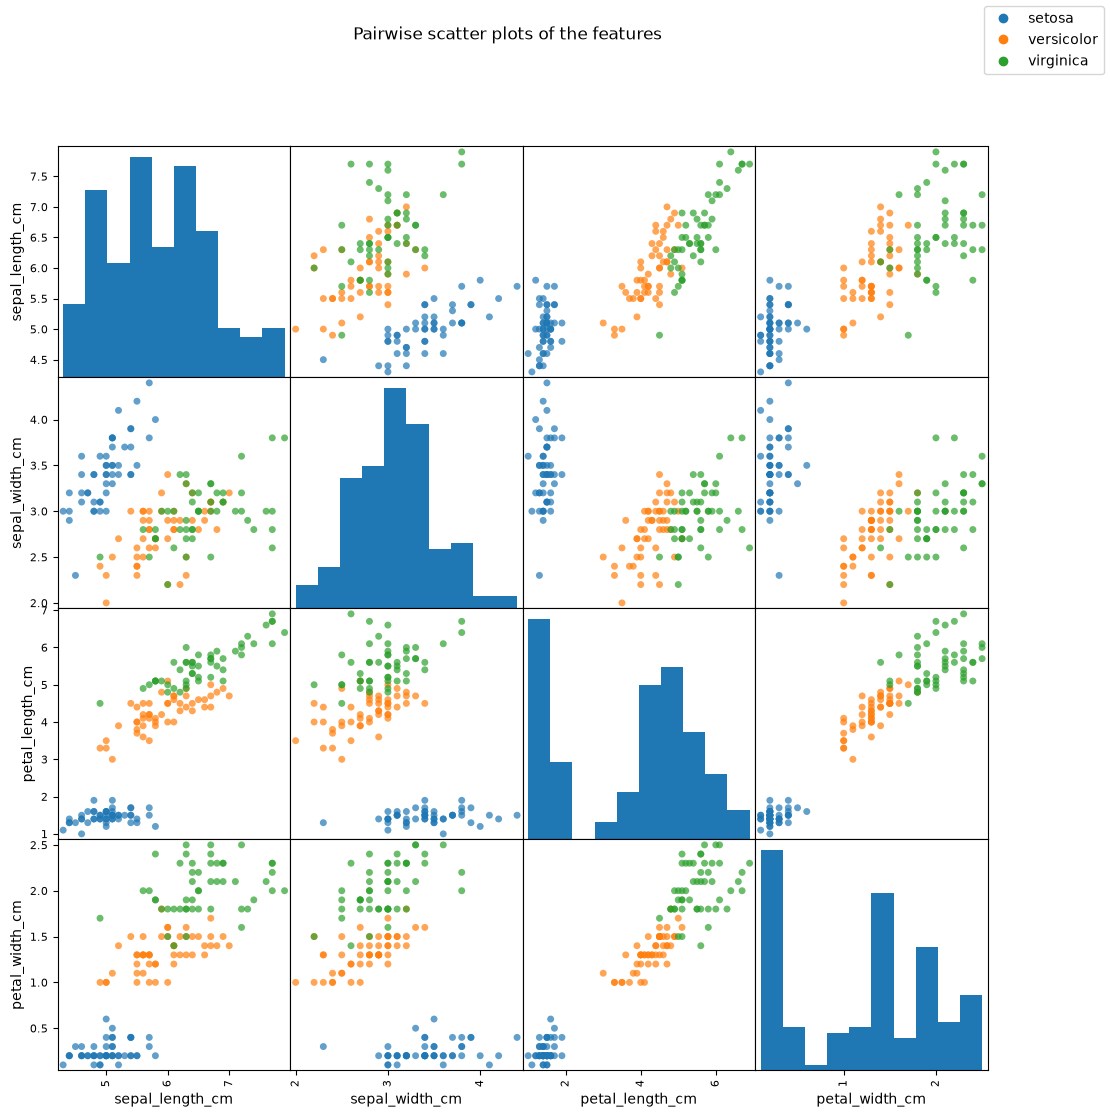

In [9]:
species = sorted(y.unique())
colors = {"setosa": "tab:blue", "versicolor": "tab:orange", "virginica": "tab:green"}

# distributions of each feature
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), feature_cols):
    bins = np.linspace(df[col].min(), df[col].max(), 25)
    for s in species:
        ax.hist(df.loc[y == s, col], bins=bins, alpha=0.6, label=s, color=colors[s])
    ax.set_title(col)
    ax.set_xlabel("cm")
    ax.set_ylabel("count")
    ax.legend()
fig.suptitle("Feature distributions per species")
plt.tight_layout()
plt.show()

# relations between features (scatter plot)
axes = pd.plotting.scatter_matrix(X, c=y.map(colors), figsize=(12, 12), diagonal="hist",
                                  alpha=0.7, marker="o", s=25)
handles = [plt.Line2D([], [], marker="o", ls="", color=colors[s], label=s) for s in species]
plt.gcf().legend(handles=handles, loc="upper right")
plt.suptitle("Pairwise scatter plots of the features")
plt.show()

* In the histograms of the sepal features (length and width), setose is separated from the other two species. Versicolor and virginica overlap slightly.
* For the sepal features, all 3 distributions overlap a lot.
* The best-separating feature pair is **petal length vs. petal width**. Petal length vs. sepal length/width and petal width vs. sepal features also separate the species well. **Sepal length vs. sepal width** is the worst pair: versicolor and virginica are mixed together.
* **Setosa** should be easy to recognize, while **versicolor and virginica** are harder, because their distributions overlap.

---

# Data Preparation
Please prepare the data in a training and a test dataset to train and test the classification model in a later stage.
Please do some research to understand the reason.
What does the parameter `stratify` do, and why is it useful here?

In [ ]:
# 0.7 train - 0.3 test
# stratify=y keeps the class proportions identical in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE
)

print("Training set:", X_train.shape, " Test set:", X_test.shape)
print("\nClass distribution training set:\n", y_train.value_counts())
print("\nClass distribution test set:\n", y_test.value_counts())

Training set: (105, 4)  Test set: (45, 4)

Class distribution training set:
 species
versicolor    35
setosa        35
virginica     35
Name: count, dtype: int64

Class distribution test set:
 species
virginica     15
versicolor    15
setosa        15
Name: count, dtype: int64


* **Why split?** We need to evaluate our model on unseen data (data that is not in the training set). Without doing so, we would only test if the model can "memorize" the training data and not if it can generalize to new data.
* **Stratify** Splits the data, so the class proportions are maintained in across the differnt sets. In easier words: each set will have the same ratio of classes as the original dataset.

---

# Model Training and Test
Train a k-nearest neighbours classifier (k-NN) and use the test data to evaluate the model's performance on unknown data.
Please investigate how the model can be influenced: test different values for k, test a second model (e.g. a decision tree), and test reducing the features to the most relevant ones.

Compare your k-NN model with the other classifiers from the lecture: logistic regression, decision tree and support vector machine (SVM). Which one would you choose?

k-NN (k=5) test accuracy: 0.911
Best k (based on training data CV): k=8 (CV acc=0.971, test acc=0.911)


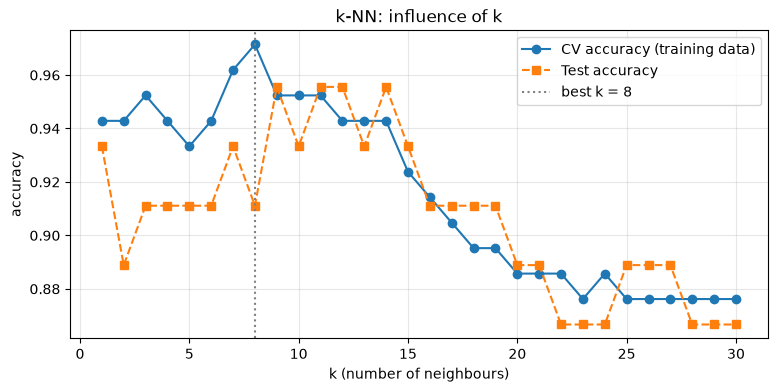


Decision tree (max_depth=3) test accuracy: 0.978
Feature importances of the tree:
petal_length_cm    0.551
petal_width_cm     0.449
sepal_width_cm     0.000
sepal_length_cm    0.000
dtype: float64

k-NN (k=8) all 4 features   test accuracy: 0.911
k-NN (k=8) petal features only test accuracy: 0.911
k-NN (k=8) sepal features only test accuracy: 0.733


In [17]:
# baseline k=5
# knn works with distances --> standardize
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn.fit(X_train, y_train)
print(f"k-NN (k=5) test accuracy: {accuracy_score(y_test, knn.predict(X_test)):.3f}")

# Test influence of k
# our dataset is small, meaning we would measure lots of noise
# --> use 5 folds of cv on the training data
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
k_values = range(1, 31)
test_acc, cv_acc = [], []
for k in k_values:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    cv_acc.append(cross_val_score(model, X_train, y_train, cv=cv).mean())
    test_acc.append(model.fit(X_train, y_train).score(X_test, y_test))

best_k = list(k_values)[int(np.argmax(cv_acc))]
print(f"Best k (based on training data CV): k={best_k} "
      f"(CV acc={max(cv_acc):.3f}, test acc={test_acc[best_k - 1]:.3f})")

plt.figure(figsize=(9, 4))
plt.plot(k_values, cv_acc, "o-", label="CV accuracy (training data)")
plt.plot(k_values, test_acc, "s--", label="Test accuracy")
plt.axvline(best_k, color="grey", ls=":", label=f"best k = {best_k}")
plt.xlabel("k (number of neighbours)")
plt.ylabel("accuracy")
plt.title("k-NN: influence of k")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# final knn model with best k
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
knn.fit(X_train, y_train)

# second model: decision tree
tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(X_train, y_train)
print(f"\nDecision tree (max_depth=3) test accuracy: {tree.score(X_test, y_test):.3f}")
print("Feature importances of the tree:")
print(pd.Series(tree.feature_importances_, index=feature_cols).sort_values(ascending=False).round(3))

# reducing the features to the most relevant ones (petal length & width)
petal_cols = ["petal_length_cm", "petal_width_cm"]
knn_petal = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
knn_petal.fit(X_train[petal_cols], y_train)
print(f"\nk-NN (k={best_k}) all 4 features   test accuracy: {knn.score(X_test, y_test):.3f}")
print(f"k-NN (k={best_k}) petal features only test accuracy: {knn_petal.score(X_test[petal_cols], y_test):.3f}")
sepal_cols = ["sepal_length_cm", "sepal_width_cm"]
knn_sepal = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
knn_sepal.fit(X_train[sepal_cols], y_train)
print(f"k-NN (k={best_k}) sepal features only test accuracy: {knn_sepal.score(X_test[sepal_cols], y_test):.3f}")

In [ ]:
# compare with some other classifiers
models = {
    f"k-NN (k={best_k})": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k)),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision tree (depth 3)": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
    # CalibratedClassifierCV gives the SVM class probabilities (needed later for predict_proba)
    "SVM (RBF kernel)": make_pipeline(StandardScaler(),
                                      CalibratedClassifierCV(SVC(kernel="rbf"), ensemble=False)),
}

results = []
for name, model in models.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv)
    model.fit(X_train, y_train)
    results.append({
        "model": name,
        "CV accuracy (mean)": cv_scores.mean(),
        "CV accuracy (std)": cv_scores.std(),
        "test accuracy": model.score(X_test, y_test),
    })

results = pd.DataFrame(results).set_index("model").sort_values("CV accuracy (mean)", ascending=False)
display(results.round(3))

,CV accuracy (mean),CV accuracy (std),test accuracy
model,,,
Logistic regression,0.981,0.023,0.911
k-NN (k=8),0.971,0.038,0.911
SVM (RBF kernel),0.971,0.038,0.933
Decision tree (depth 3),0.952,0.043,0.978


* **Influence of k:** In knn, k decides how many neighbors are considered when making a prediction. In Pattern Recognition there is the concept of a decision boundary. A small k leads to a too sensitve decision boundary (reacting to noise), and a too large k smoothes the decision boundary too much. We basically need to find a sweet spot.
* **Decision tree:** The Decision Tree only uses the petal features and reaches high test accuracy (even with small depth). But this is expecable when looking at the plots above.
* **kNN with reduced features** almost performs as well as the full feature set. Petal features seem to carry most of the inforarmation needed to make a prediction

**What to use?**
I would use the Decision Tree for this problem, as it is simple, easy to interpret and performs the best.

---

# Evaluation of the Model Quality
Evaluate the model with the accuracy and a confusion matrix.
Which species are confused with each other? Calculate precision and recall for one species by hand and compare with the classification report.

Accuracy: 0.911



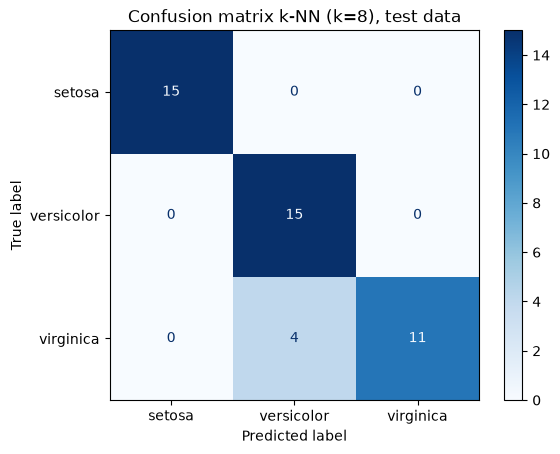

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,true,predicted
133,6.3,2.8,5.1,1.5,virginica,versicolor
127,6.1,3.0,4.9,1.8,virginica,versicolor
138,6.0,3.0,4.8,1.8,virginica,versicolor
106,4.9,2.5,4.5,1.7,virginica,versicolor


versicolor: TP=15, FP=4, FN=0
Precision by hand = TP/(TP+FP) = 15/19 = 0.789
Recall by hand    = TP/(TP+FN) = 15/15 = 1.000
sklearn precision = 0.789, sklearn recall = 1.000

              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      0.789     1.000     0.882        15
   virginica      1.000     0.733     0.846        15

    accuracy                          0.911        45
   macro avg      0.930     0.911     0.910        45
weighted avg      0.930     0.911     0.910        45



In [13]:
# Evaluate the final k-NN model on the test data
y_pred = knn.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}\n")

labels = knn.classes_
cm = confusion_matrix(y_test, y_pred, labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues")
plt.title(f"Confusion matrix k-NN (k={best_k}), test data")
plt.show()

# Which samples were misclassified?
errors = X_test[y_test != y_pred].assign(true=y_test[y_test != y_pred], predicted=y_pred[y_test != y_pred])
display(errors)

# Precision and recall by hand for "versicolor"
cls = "versicolor"
i = list(labels).index(cls)
TP = cm[i, i]                 # correctly predicted versicolor
FP = cm[:, i].sum() - TP      # predicted versicolor but actually another species (column)
FN = cm[i, :].sum() - TP      # actually versicolor but predicted as another species (row)
precision_manual = TP / (TP + FP)
recall_manual = TP / (TP + FN)
print(f"{cls}: TP={TP}, FP={FP}, FN={FN}")
print(f"Precision by hand = TP/(TP+FP) = {TP}/{TP + FP} = {precision_manual:.3f}")
print(f"Recall by hand    = TP/(TP+FN) = {TP}/{TP + FN} = {recall_manual:.3f}")
print(f"sklearn precision = {precision_score(y_test, y_pred, labels=[cls], average=None)[0]:.3f}, "
      f"sklearn recall = {recall_score(y_test, y_pred, labels=[cls], average=None)[0]:.3f}\n")

print(classification_report(y_test, y_pred, digits=3))

* The kNN model predicted 41 out of 45 flowers correctly on the test set.
* **Setosa is never confused.** All errors are between **versicolor and virginica**.

# Classify a New Flower
Use your trained model to predict the species of a new flower, e.g. sepal length 6.3 cm, sepal width 2.9 cm, petal length 5.1 cm, petal width 1.7 cm.
How certain is the model?

In [ ]:
# New flower (in cm)
new_flower = pd.DataFrame([[6.3, 2.9, 5.1, 1.7]], columns=feature_cols)

print("k-NN prediction:", knn.predict(new_flower)[0])
proba = pd.Series(knn.predict_proba(new_flower)[0], index=knn.classes_)
print("k-NN class probabilities (share of the k neighbours):")
print(proba.round(3), "\n")

# what we do now (basically):
# have a scatter plot of all our training samples
# draw the dot of the new flower in and see in what cluster it lands
scaler, knn_clf = knn.named_steps["standardscaler"], knn.named_steps["kneighborsclassifier"]
dist, idx = knn_clf.kneighbors(scaler.transform(new_flower))
display(X_train.iloc[idx[0]].assign(species=y_train.iloc[idx[0]].values, distance=dist[0].round(3)))

# Second opinion from the other models
for name, model in models.items():
    p = pd.Series(model.predict_proba(new_flower)[0], index=model.classes_)
    print(f"{name:25s} -> {model.predict(new_flower)[0]:10s} probabilities: {p.round(2).to_dict()}")

k-NN prediction: virginica
k-NN class probabilities (share of the k neighbours):
setosa        0.000
versicolor    0.375
virginica     0.625
dtype: float64 



,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,distance
103,6.3,2.9,5.6,1.8,virginica,0.310
126,6.2,2.8,4.8,1.8,virginica,0.327
123,6.3,2.7,4.9,1.8,virginica,0.472
54,6.5,2.8,4.6,1.5,versicolor,0.499
137,6.4,3.1,5.5,1.8,virginica,0.524
149,5.9,3.0,5.1,1.8,virginica,0.531
78,6.0,2.9,4.5,1.5,versicolor,0.550
83,6.0,2.7,5.1,1.6,versicolor,0.576


k-NN (k=8)                -> virginica  probabilities: {'setosa': 0.0, 'versicolor': 0.38, 'virginica': 0.62}
Logistic regression       -> virginica  probabilities: {'setosa': 0.0, 'versicolor': 0.42, 'virginica': 0.58}
Decision tree (depth 3)   -> virginica  probabilities: {'setosa': 0.0, 'versicolor': 0.03, 'virginica': 0.97}
SVM (RBF kernel)          -> virginica  probabilities: {'setosa': 0.01, 'versicolor': 0.1, 'virginica': 0.89}


* **Decision tree** is again the best

# Discuss the results

**Discussion of the results**

* **Data:** The Iris dataset is small (150 samples), clean (no missing values) and balanced (50 per class). The petal measurements are by far the most informative features. Setosa is perfectly separable, while versicolor and virginica overlap slightly.
* **Preparation:** A stratified 70/30 train/test split gives an independent test set with the same class distribution. Standardising the features (inside a pipeline, fitted only on the training data) is important for distance-based (k-NN) and margin-based (SVM) models and for regularised logistic regression.
* **Models:** k-NN, logistic regression, SVM and decision tree all reach about 91–98 % accuracy. The differences between the models are smaller than the uncertainty caused by the small test set (one flower = 2.2 %). Cross-validation on the training data is therefore a more reliable basis for choosing hyperparameters (k) and comparing models than a single test split.
* **Errors:** All errors are versicolor ↔ virginica confusions in the overlapping region. Setosa is always classified correctly. Precision and recall show *how* the model fails: here virginica flowers with small petals are predicted as versicolor (low recall for virginica, low precision for versicolor).
* **Feature reduction:** The two petal features alone give the same accuracy as all four features. A simpler model with fewer measurements is enough.
* **Limitations / next steps:** Because the dataset is small, the results depend on the random split. Repeated or nested cross-validation would give more robust estimates. The remaining errors cannot be removed completely, because the classes really overlap in feature space. Predictions near the boundary (like the new flower) should be reported together with their (low) certainty.